## Module Titile: Strategic Thinking

## Assignment Titile: CA 3 Final Submission

## Project Titile: Predicting Repeat Purchases in E-Commerce Using Interpretable Machine Learning



In [2]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [26]:
# Load the dataset

df = pd.read_csv("Online_Retail.csv") 

## Data Understanding

#### Dataset Overview

In [27]:
# Preview the data

print(df.head())

  InvoiceNo StockCode                          Description  Quantity  \
0    536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1    536365     71053                  WHITE METAL LANTERN         6   
2    536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3    536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4    536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   

        InvoiceDate  UnitPrice  CustomerID         Country  
0  01/12/2010 08:26       2.55     17850.0  United Kingdom  
1  01/12/2010 08:26       3.39     17850.0  United Kingdom  
2  01/12/2010 08:26       2.75     17850.0  United Kingdom  
3  01/12/2010 08:26       3.39     17850.0  United Kingdom  
4  01/12/2010 08:26       3.39     17850.0  United Kingdom  


In [28]:
# Basic structure

print("Shape of dataset:", df.shape)
print("\nColumn names:\n", df.columns.tolist())

Shape of dataset: (541909, 8)

Column names:
 ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [29]:
# Data types and non-null counts

print("\nData info:")
df.info()


Data info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB


In [30]:
# Check missing values

print("\nMissing values per column:")

print(df.isnull().sum())


Missing values per column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [31]:
# Unique values per column
print("\nUnique value counts per column:")

print(df.nunique().sort_values())


Unique value counts per column:
Country           38
Quantity         722
UnitPrice       1630
StockCode       4070
Description     4223
CustomerID      4372
InvoiceDate    23260
InvoiceNo      25900
dtype: int64


In [32]:
# Identify rows that are duplicated across all columns
duplicate_rows = df[df.duplicated(keep=False)]

# Display number of full duplicates
print(f"Number of fully duplicated rows: {duplicate_rows.shape[0]}")

# Preview the duplicated rows
print(duplicate_rows.head())

Number of fully duplicated rows: 10147
    InvoiceNo StockCode                       Description  Quantity  \
485    536409     22111      SCOTTIE DOG HOT WATER BOTTLE         1   
489    536409     22866     HAND WARMER SCOTTY DOG DESIGN         1   
494    536409     21866       UNION JACK FLAG LUGGAGE TAG         1   
517    536409     21866       UNION JACK FLAG LUGGAGE TAG         1   
521    536409     22900   SET 2 TEA TOWELS I LOVE LONDON          1   

          InvoiceDate  UnitPrice  CustomerID         Country  
485  01/12/2010 11:45       4.95     17908.0  United Kingdom  
489  01/12/2010 11:45       2.10     17908.0  United Kingdom  
494  01/12/2010 11:45       1.25     17908.0  United Kingdom  
517  01/12/2010 11:45       1.25     17908.0  United Kingdom  
521  01/12/2010 11:45       2.95     17908.0  United Kingdom  


In [33]:
print("\n Summary statistics for numeric columns:")

print(df[['Quantity', 'UnitPrice']].describe())


 Summary statistics for numeric columns:
            Quantity      UnitPrice
count  541909.000000  541909.000000
mean        9.552250       4.611114
std       218.081158      96.759853
min    -80995.000000  -11062.060000
25%         1.000000       1.250000
50%         3.000000       2.080000
75%        10.000000       4.130000
max     80995.000000   38970.000000


#### EDA (Exploratory Data Analysis)

##### Feature Distributions

Rationale: Understanding the distribution of numeric features helps identify skewness, modality, and outliers. This informs decisions about scaling, transformation, and filtering.

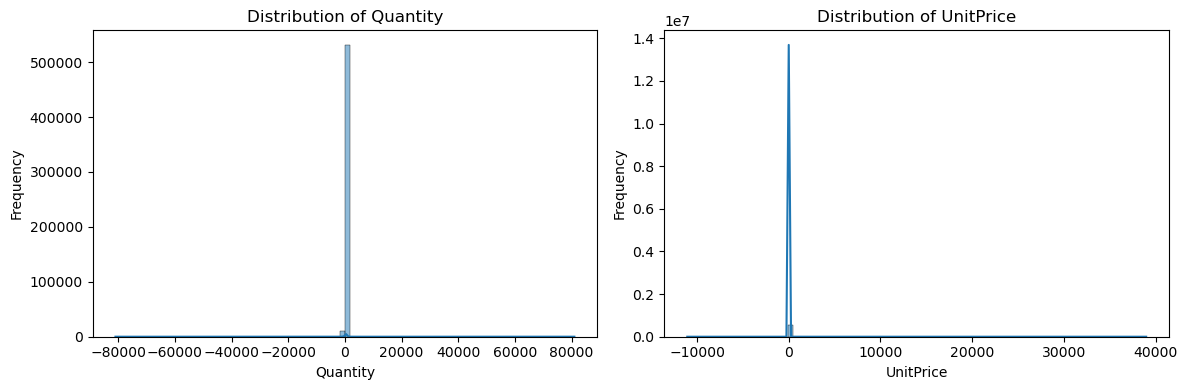

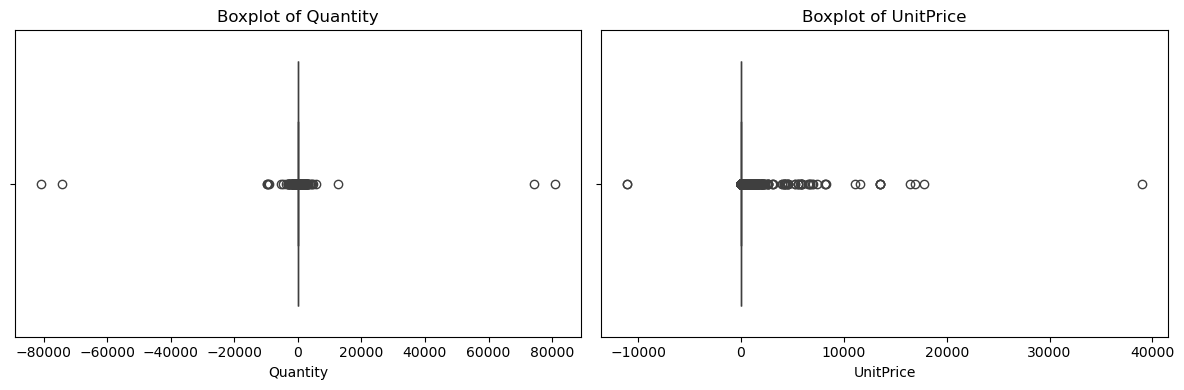

In [34]:
# Select numeric columns
numeric_cols = ['Quantity', 'UnitPrice']

# Histograms
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(1, len(numeric_cols), i+1)
    sns.histplot(df[col], bins=100, kde=True)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

# Boxplots
plt.figure(figsize=(12, 4))
for i, col in enumerate(numeric_cols):
    plt.subplot(1, len(numeric_cols), i+1)
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
plt.tight_layout()
plt.show()

Rationale: Count plots reveal dominant categories, rare values, and potential encoding needs.

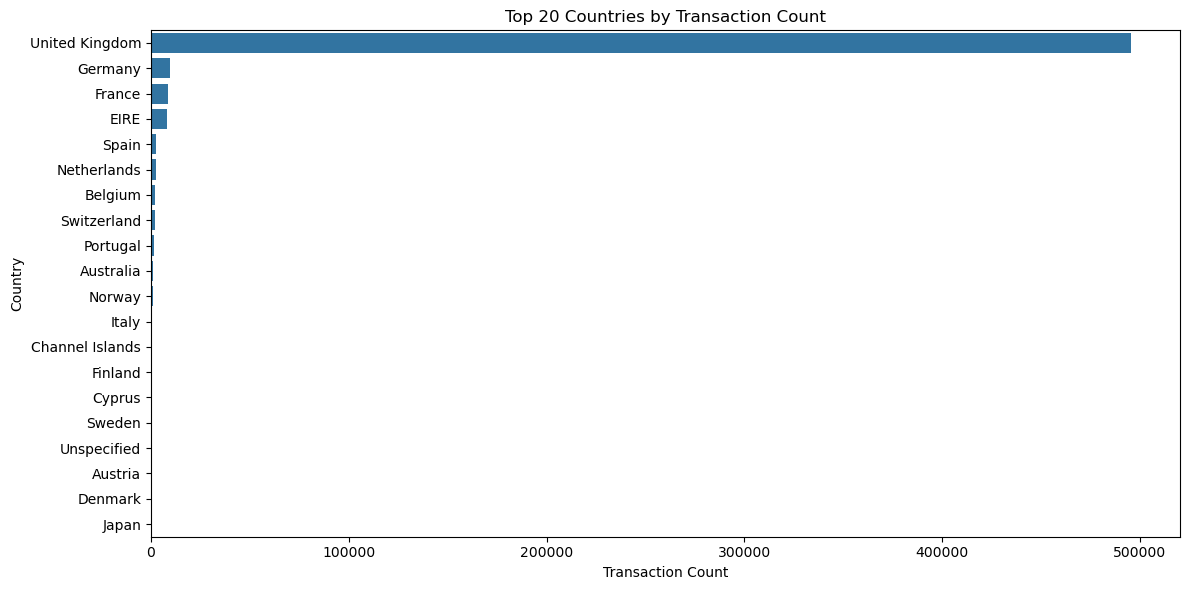

In [35]:
# Count plot for Country

top_countries = df['Country'].value_counts().head(20)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_countries.values, y=top_countries.index)
plt.title('Top 20 Countries by Transaction Count')
plt.xlabel('Transaction Count')
plt.ylabel('Country')
plt.tight_layout()
plt.show()


##### Correlation Matrix

Rationale: Identifies linear relationships between numeric features to guide feature selection and multicollinearity checks.

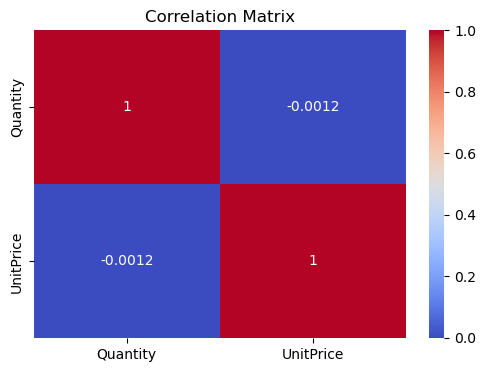

In [36]:
# Correlation matrix
plt.figure(figsize=(6, 4))
sns.heatmap(df[['Quantity', 'UnitPrice']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

##### Outlier Detection

Rationale: Quantifies extreme values to inform filtering or transformation decisions.

In [37]:
# IQR-based outlier detection for Quantity and UnitPrice
numeric_cols = ['Quantity', 'UnitPrice']

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f" Number of outliers in {col}: {outliers.shape[0]}")


 Number of outliers in Quantity: 58619
 Number of outliers in UnitPrice: 39627


##### Initial Hypotheses for Feature Engineering

Based on business intuition and exploratory analysis, the following hypotheses will guide feature creation:

1. Customers with higher **purchase frequency** (`transactions_per_customer`) are more likely to repeat purchases.  

2. Customers with higher **total spend** (`total_spend_per_customer`) are more likely to repeat purchases

3. **Shorter time gaps** (`avg_days_between_purchases`) between purchases increase repeat likelihood.

These features will be engineered and later interpreted using LIME to assess their influence on repeat purchase predictions.


#### Data Preparation

In [39]:
# Drop rows with missing CustomerID (essential for customer-level features)
df = df.dropna(subset=['CustomerID'])

In [40]:
# Convert CustomerID to integer
df['CustomerID'] = df['CustomerID'].astype(int)

In [41]:
# Convert InvoiceDate to datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], dayfirst=True)

In [42]:
# Remove negative or zero UnitPrice and Quantity (invalid transactions or returns)
df = df[(df['UnitPrice'] > 0) & (df['Quantity'] > 0)]

In [44]:
# Remove full duplicates
df = df.drop_duplicates()